# Mobilidade urbana e mercado imobiliário no Rio de Janeiro (2011–2024)

**Ana Alice Silva · Mayara A. P. Bomback · Henrique Lara**  
FGV EMAp — Análise Exploratória de Dados e Visualização, 2026.2

*Rascunho para a entrega intermediária. Os resultados poderão ser revisados até a entrega final.*

## Resumo

Investigamos a associação entre proximidade ao transporte público e preços por m² de transações residenciais no Rio de Janeiro (2011–2024). Esta entrega parcial descreve a proximidade ao Metrô, BRT e VLT e compara medianas de preços para Metrô e BRT, com limiar de 500 m e filtros de área e preço. No Metrô, a diferença entre as medianas gerais é de 83,39%, e a mediana das diferenças por bairro, ano e tipologia é de 1,73%. No BRT, as medidas ficam próximas de zero. Os resultados são descritivos e cobrem apenas parte das perguntas; a análise completa incluirá as quatro modalidades, inclusive o BRS.


## 1. Introdução

A infraestrutura de transporte público amplia as possibilidades de deslocamento e constitui uma característica relevante da localização dos imóveis. Investigar sua associação com os preços ajuda a compreender diferenças espaciais do mercado imobiliário. Essa relação também depende do bairro, do período e das características dos imóveis, exigindo cuidado na comparação de transações próximas e distantes.

O projeto examina transações residenciais no Rio de Janeiro entre 2011 e 2024 e sua relação com Metrô, BRT, VLT e BRS. Nesta etapa, a comparação geral do Metrô apresenta uma diferença de preços maior que a comparação dentro de grupos de bairro, ano e tipologia; no BRT, ambas as medidas estão próximas de zero. Essas estatísticas descrevem conjuntos distintos e não identificam efeito causal.

O artigo apresenta os dados, a integração espacial e as oito perguntas da proposta. Os espaços de contribuição dos colegas e as análises previstas para a próxima entrega estão identificados.


## 2. Dados imobiliários — ITBI

*Mayara: integrar a origem e cobertura da base municipal de 2011–2024, os campos utilizados, a seleção residencial, a limpeza e as derivações de área e preço por m² efetivamente realizadas em `01_itbi.ipynb`.*

## 3. Dados de mobilidade


### 3.1. Preparação espacial

As camadas de Metrô, BRT e VLT do Data.Rio representam pontos de embarque; o BRS é representado por corredores e foi tratado separadamente. Em `02_mobilidade.ipynb`, foram examinadas as geometrias e as informações de início de operação, com projeção para **EPSG:31983**, que permite calcular distâncias em metros.

### 3.2. Complementação dos anos de operação

A base geográfica do **VLT não informava datas de inauguração**. O grupo acrescentou anos de início de operação a partir das fontes históricas listadas nas referências. São informações adicionadas pelo grupo, não datas completas do dataset; **Itamaraty permaneceu sem ano identificado**, e as atribuições individuais ainda requerem validação. No BRS, datas inconsistentes em Centro-Tijuca e Passos não foram substituídas por anos presumidos.


## 4. Integração e metodologia

### 4.1. Distâncias e disponibilidade histórica

O CSV integrado associa cada transação residencial geocodificada ao ano, bairro, tipologia, área, preço por m² e distâncias em linha reta às estações de Metrô, BRT e VLT consideradas disponíveis naquele ano. O procedimento está em `03_integracao_itbi.ipynb`. A base ainda não contém distância ao BRS; seu critério de acesso será definido na próxima entrega, distinguindo corredor de ponto de embarque.

Transações a **até 500 m** são classificadas como próximas; acima desse limiar, como distantes. Distâncias ausentes ou inválidas são excluídas da classificação. O uso de anos de operação não distingue o mês de inauguração.

O código e as instruções de reprodução estão no [repositório do projeto](https://github.com/ana-alice17/mobilidade-imobiliario-rj).


### 4.2. Recorte de preços

Selecionamos área finita **≥ 25 m²** e **0 < preço por m² ≤ R$ 100.000**, obtendo **315.284 transações**. O filtro reduz a influência de áreas pequenas e valores extremos, sem certificar a validade de cada registro. A saída de carregamento informa a retenção em relação à base integrada.


### 4.3. Contexto espacial

A figura apresenta a proporção anual de transações a até 500 m do Metrô, BRT e VLT, usando como denominador as transações com distância válida para cada modalidade e ano. Utiliza a base integrada antes do filtro de preços; não representa a parcela de residências da cidade atendida pelo transporte. O BRS ainda não está incluído.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ=Path.cwd().resolve()
if RAIZ.name=="notebooks":
    RAIZ=RAIZ.parent
"""Cálculos descritivos compartilhados pelos notebooks 03 e 05."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODAIS = {"Metrô": "dist_metro_m", "BRT": "dist_brt_m", "VLT": "dist_vlt_m"}
CHAVES = ["nm_bairro_norm", "ano", "ds_imovel_tipologia"]

def preparar(dados):
    dados = dados.copy()
    obrigatorias = set(CHAVES + ["area", "valor_m2", *MODAIS.values()])
    if obrigatorias - set(dados):
        raise ValueError(f"Colunas ausentes: {sorted(obrigatorias - set(dados))}")
    for col in ["area", "valor_m2", "ano", *MODAIS.values()]:
        dados[col] = pd.to_numeric(dados[col], errors="coerce")
    if "id_transacao" in dados and (dados.id_transacao.isna().any() or not dados.id_transacao.is_unique):
        raise ValueError("Identificadores de transação ausentes ou duplicados.")
    amostra = dados.loc[np.isfinite(dados.area) & dados.area.ge(25)
                        & dados.valor_m2.gt(0) & dados.valor_m2.le(100_000)].copy()
    return dados, amostra

def distancia_valida(df, col):
    return np.isfinite(df[col]) & df[col].ge(0)

def comparar(amostra, limite=500, minimo=10):
    resultados, detalhes = [], {}
    for modal in ["Metrô", "BRT"]:
        col = MODAIS[modal]
        base = amostra.loc[distancia_valida(amostra,col)].copy()
        base["perto"] = base[col].le(limite)
        completa = base.dropna(subset=CHAVES)
        for chave in ["nm_bairro_norm", "ds_imovel_tipologia"]:
            completa = completa.loc[completa[chave].astype(str).str.strip().ne("")]
        agregado = completa.groupby(CHAVES + ["perto"]).valor_m2.agg(n="size", mediana="median")
        n = agregado.n.unstack("perto").reindex(columns=[False,True],fill_value=0).fillna(0)
        med = agregado.mediana.unstack("perto").reindex(columns=[False,True])
        g = pd.DataFrame({"n_longe":n[False], "n_perto":n[True],
                          "mediana_longe":med[False], "mediana_perto":med[True]})
        g = g.loc[g.n_longe.ge(minimo)&g.n_perto.ge(minimo)].copy()
        g["diferenca_pct"] = 100*(g.mediana_perto/g.mediana_longe-1)
        detalhes[modal] = g
        geral = base.groupby("perto").valor_m2.median().reindex([False,True])
        incluidos = int(g[["n_longe","n_perto"]].to_numpy().sum())
        resultados.append(dict(modalidade=modal,n_amostra=len(amostra),n_distancia_valida=len(base),
            n_chaves_completas=len(completa),grupos_avaliados=len(n),grupos_comparaveis=len(g),
            cobertura_grupos_pct=100*len(g)/len(n) if len(n) else np.nan,
            n_transacoes_comparaveis=incluidos,
            cobertura_amostra_pct=100*incluidos/len(amostra) if len(amostra) else np.nan,
            cobertura_distancia_valida_pct=100*incluidos/len(base) if len(base) else np.nan,
            mediana_geral_longe=geral[False],mediana_geral_perto=geral[True],
            diferenca_geral_pct=100*(geral[True]/geral[False]-1),
            mediana_diferencas_grupos_pct=g.diferenca_pct.median()))
    return pd.DataFrame(resultados), detalhes

def tabela_artigo(resumo):
    tabela = resumo.set_index("modalidade")[["diferenca_geral_pct","mediana_diferencas_grupos_pct",
        "grupos_comparaveis","n_transacoes_comparaveis","cobertura_amostra_pct"]].rename(columns={
        "diferenca_geral_pct":"Diferença geral (%)", "mediana_diferencas_grupos_pct":"Diferença por grupo¹ (%)",
        "grupos_comparaveis":"Grupos", "n_transacoes_comparaveis":"Transações", "cobertura_amostra_pct":"Cobertura² (%)"})
    tabela.index.name="Modalidade"
    return tabela.round(2)

def evolucao_proximidade(dados):
    proporcao = pd.DataFrame(index=sorted(dados.ano.dropna().unique()))
    denominadores = pd.DataFrame(index=proporcao.index)
    for modal,col in MODAIS.items():
        validas = dados.loc[distancia_valida(dados,col)]
        denominadores[modal] = validas.groupby("ano").size().reindex(proporcao.index,fill_value=0)
        proporcao[modal] = validas[col].le(500).groupby(validas.ano).mean()*100
    proporcao.index.name=denominadores.index.name="Ano"
    return proporcao,denominadores

def figura_proximidade(proporcao):
    fig,ax=plt.subplots(figsize=(8,3.4))
    proporcao.plot(ax=ax,marker="o",markersize=3)
    ax.set(xlabel="Ano",ylabel="Transações com distância válida (%)",
           title="Transações a até 500 m — Metrô, BRT e VLT")
    ax.grid(axis="y",alpha=.2)
    fig.tight_layout()
    return fig

def figura_comparacao(resumo):
    fig,eixos=plt.subplots(1,2,figsize=(9,3.5))
    tabela=resumo.set_index("modalidade")
    tabela[["diferenca_geral_pct","mediana_diferencas_grupos_pct"]].rename(columns={
        "diferenca_geral_pct":"Geral", "mediana_diferencas_grupos_pct":"Por grupo¹"}).plot.bar(ax=eixos[0],rot=0)
    eixos[0].set(title="Diferenças entre medianas",ylabel="Diferença (%)",xlabel="")
    eixos[0].axhline(0,color="black",linewidth=.7)
    tabela[["cobertura_amostra_pct","cobertura_grupos_pct"]].rename(columns={
        "cobertura_amostra_pct":"Transações²", "cobertura_grupos_pct":"Grupos³"}).plot.bar(ax=eixos[1],rot=0)
    eixos[1].set(title="Cobertura da comparação",ylabel="Cobertura (%)",xlabel="",ylim=(0,100))
    for ax in eixos:
        ax.grid(axis="y",alpha=.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


# Use a saída atual da integração ou sua cópia compactada.
ARQUIVO=RAIZ/"data/processed/itbi_com_distancias.csv"
if not ARQUIVO.is_file():
    ARQUIVO=RAIZ/"data/processed/itbi_com_distancias.csv.gz"
if not ARQUIVO.is_file():
    raise FileNotFoundError("Base ausente. Consulte as instruções do README.")
dados,amostra=preparar(pd.read_csv(ARQUIVO,low_memory=False))

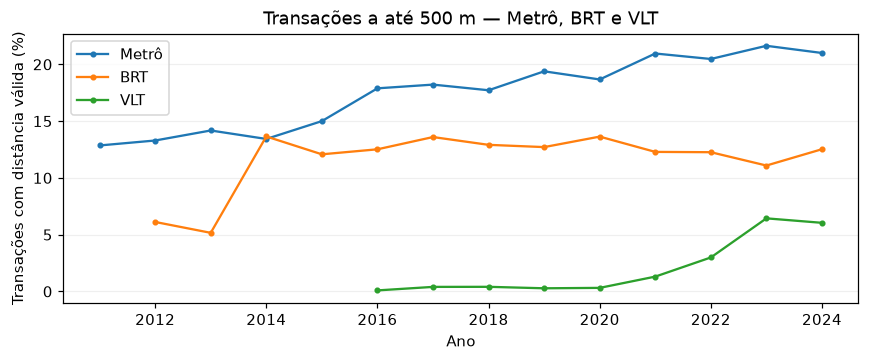

In [2]:
evolucao,cobertura_anual=evolucao_proximidade(dados)
figura_proximidade(evolucao)
plt.show()


Mudanças nas proporções podem refletir a infraestrutura cadastrada, a disponibilidade das distâncias e a concentração de transações em poucos endereços. A figura contextualiza a integração; não responde à pergunta 8 sobre a evolução dos preços.


## 5. Perguntas e resultados


### 5.1. Como os valores dos imóveis negociados pelo ITBI se distribuem no município do Rio de Janeiro?

*Henrique: integrar os procedimentos de agregação, a visualização da distribuição e sua interpretação.*


### 5.2. Qual é o valor médio e mediano do m² dos imóveis analisados e qual é a diferença entre essas medidas?

*Henrique: integrar o cálculo das duas medidas e a interpretação de sua diferença.*


### 5.3. Qual é a dispersão dos valores do m², considerando variância, desvio padrão e amplitude?

*Henrique: integrar as medidas de dispersão, as visualizações pertinentes e sua interpretação.*


### 5.4. Os valores do m² apresentam distribuição semelhante entre diferentes bairros ou regiões da cidade?

*Henrique: integrar as agregações por bairro ou região, a comparação visual e sua análise.*


### 5.5. Qual é o valor médio e mediano do m² para imóveis localizados próximos e distantes dos pontos de acesso de Metrô, BRT, VLT e BRS?

**Resultado parcial — medianas de Metrô e BRT.** Usamos o recorte da seção 4.2 e o limiar de 500 m. Na comparação geral, calculamos 100 × (mediana perto / mediana longe − 1). Repetimos esse cálculo dentro de cada grupo de **bairro, ano e tipologia** com chaves completas e **pelo menos 10 transações perto e 10 longe**, resumindo as diferenças pela mediana, com peso igual por grupo.

A tabela apresenta as diferenças e a cobertura das transações; o gráfico mostra também a proporção de grupos elegíveis. As médias e as comparações de VLT e BRS serão completadas na próxima entrega.


In [3]:
resumo,grupos_por_modal=comparar(amostra)
display(tabela_artigo(resumo))
display(Markdown("¹ Mediana das diferenças percentuais dos grupos. ² Transações dos grupos / amostra de preços."))


,Diferença geral (%),Diferença por grupo¹ (%),Grupos,Transações,Cobertura² (%)
Modalidade,,,,,
Metrô,83.39,1.73,291,107385,34.06
BRT,-0.41,0.35,304,71832,22.78


¹ Mediana das diferenças percentuais dos grupos. ² Transações dos grupos / amostra de preços.

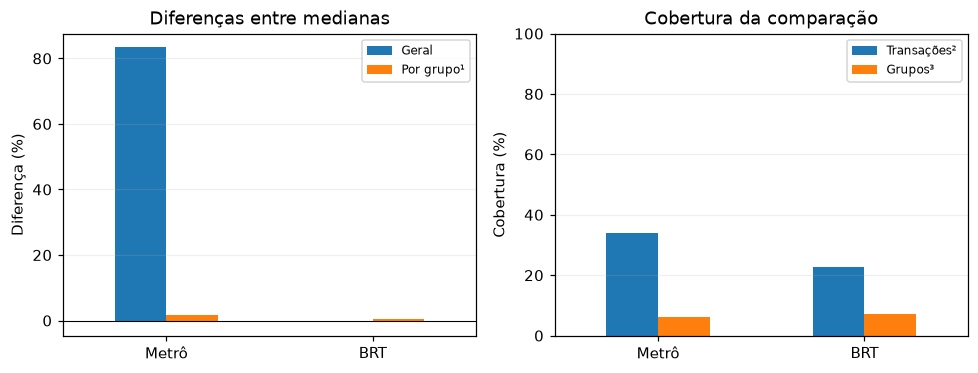

³ Grupos comparáveis / grupos avaliados com chaves completas e distância válida.

In [4]:
figura_comparacao(resumo)
plt.show()
display(Markdown("³ Grupos comparáveis / grupos avaliados com chaves completas e distância válida."))


**Interpretação.** Para o **Metrô**, a mediana de preços perto é **83,39% maior** que longe na comparação geral; a mediana das diferenças dentro dos **291 grupos comparáveis** é de **1,73%**. Esses grupos reúnem **107.385 transações**, ou **34,06% da amostra de preços**.

Para o **BRT**, as diferenças são de **−0,41%** na comparação geral e **0,35%** no resumo por grupo. Os **304 grupos** reúnem **71.832 transações**, ou **22,78% da amostra**. As medidas estão próximas de zero em termos descritivos; não foi realizado teste de significância.

As duas formas de comparação resumem estatísticas e conjuntos distintos. A discrepância no Metrô é compatível com diferenças de composição, mas não quantifica a contribuição de cada fator nem uma redução de efeito causal. Grupos excluídos podem ter características diferentes dos elegíveis.


### 5.6. A variabilidade dos valores do m² é diferente entre imóveis próximos e distantes dos pontos de acesso de Metrô, BRT, VLT e BRS?

*A finalizar na próxima entrega para as quatro modalidades.* As medianas da seção 5.5 não medem dispersão e não permitem responder a esta pergunta.


### 5.7. Existem diferenças na distribuição dos valores do m² entre imóveis próximos aos diferentes tipos de transporte?

*A finalizar na próxima entrega para Metrô, BRT, VLT e BRS.* A análise deverá comparar as distribuições e considerar transações próximas a mais de uma modalidade. As diferenças perto/longe da seção 5.5 não bastam para respondê-la.


### 5.8. Como os valores e sua variabilidade se comportam ao longo dos anos analisados?

*Mayara: integrar as agregações anuais, visualizações e interpretação da evolução dos preços e da dispersão, explicitando o tratamento da inflação e a comparabilidade dos períodos.*


## 6. Discussão e limitações

Os resultados parciais reforçam a necessidade de acompanhar as comparações agregadas com recortes comparáveis e sua cobertura. Mesmo dentro de bairro, ano e tipologia, permanecem diferenças de qualidade, área e localização. Os preços são nominais, a geocodificação tem limitações e a distância em linha reta não equivale ao percurso caminhável. A reconstrução histórica da rede depende das informações de operação disponíveis. Por isso, as associações observadas não identificam causalidade.

Na próxima entrega, a etapa de transporte completará médias, medianas, variabilidade e distribuições para **Metrô, BRT, VLT e BRS**, incluindo o critério de acesso ao BRS, a cobertura das comparações e as sobreposições entre modalidades. As verificações de concentração espacial e sensibilidade à distância também deverão ser documentadas.


## 7. Conclusão preliminar

A integração permitiu descrever a proximidade das transações ao Metrô, BRT e VLT e iniciar a comparação de preços para Metrô e BRT. No Metrô, a diferença geral é maior que o resumo dentro dos grupos comparáveis; no BRT, ambas as medidas estão próximas de zero. Como recomendação metodológica, a leitura desses resultados deve considerar a composição e a cobertura da amostra.

Esta entrega responde apenas parcialmente às perguntas de transporte. Sua conclusão depende das medidas previstas para as quatro modalidades e da integração das demais contribuições do grupo. Os achados atuais não sustentam atribuir diferenças de preço à implantação dos transportes nem recomendar investimentos específicos.


## Referências

RIO DE JANEIRO (Município). Secretaria Municipal de Fazenda. **ITBI: valores médios por m² de transações imobiliárias por trecho de logradouro**. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: <https://fazenda.prefeitura.rio/itbi-valores-medios-por-m2-de-transacoes-imobiliarias-por-trecho-de-logradouro/>. Acesso em: 17 set. 2026.

RIO DE JANEIRO (Município). Data.Rio. **Estações BRT**. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: <https://www.data.rio/datasets/f753941f44a749d4987f1111aa6486b3_0/about>. Acesso em: 17 set. 2026.

RIO DE JANEIRO (Município). Data.Rio. **Estações Metrô**. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: <https://www.data.rio/datasets/PCRJ::esta%C3%A7%C3%B5es-metr%C3%B4/about>. Acesso em: 17 set. 2026.

RIO DE JANEIRO (Município). Data.Rio. **VLT**. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: <https://www.data.rio/datasets/29cc383d2d344e8387dda153ec0d545d_9/explore?location=-22.902796%2C-43.188243%2C4.00&showTable=true>. Acesso em: 17 set. 2026.

RIO DE JANEIRO (Município). Data.Rio. **BRS (Serviço Rápido de Ônibus)**. Rio de Janeiro: Prefeitura da Cidade do Rio de Janeiro, [s. d.]. Disponível em: <https://www.data.rio/datasets/0b707ee14f3d4515ab513e7d078f0c1b_0/explore?location=-22.944023%2C-43.224749%2C2.00>. Acesso em: 17 set. 2026.

### Fontes históricas usadas na complementação do VLT

RIO DE JANEIRO (Município). **[Informações sobre a operação da Linha 1 do VLT e sua expansão até a Rodoviária]**. Rio de Janeiro: Prefeitura, 2016. Disponível em: <https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6268057>. Acesso em: 21 out. 2026.

RIO DE JANEIRO (Município). **[Informações sobre a operação da parada Gamboa do VLT]**. Rio de Janeiro: Prefeitura, 2016. Disponível em: <https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6548374>. Acesso em: 21 out. 2026.

RIO DE JANEIRO (Município). **[Informações sobre o início da operação das paradas Providência e Harmonia do VLT]**. Rio de Janeiro: Prefeitura, 2017. Disponível em: <https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=7056533>. Acesso em: 21 out. 2026.

RIO DE JANEIRO (Município). **Prefeitura inicia operação da Linha 3 do VLT que liga a Central do Brasil ao Aeroporto Santos Dumont**. Rio de Janeiro: Prefeitura, 2019. Disponível em: <https://en.prefeitura.rio/transportes/prefeitura-inicia-operacao-da-linha-3-do-vlt-que-liga-a-central-do-brasil-ao-aeroporto-santos-dumont/>. Acesso em: 21 out. 2026.

RIO DE JANEIRO (Município). **Prefeitura inaugura o Terminal Intermodal Gentileza**. Rio de Janeiro: Prefeitura, 2024. Disponível em: <https://prefeitura.rio/cidade/prefeitura-inaugura-o-terminal-intermodal-gentileza/>. Acesso em: 21 out. 2026.

*Os títulos entre colchetes descrevem o conteúdo das fontes registrado em `02_mobilidade.ipynb`; a redação original desses títulos deverá ser conferida na revisão bibliográfica final.*

### Material complementar

Código de mobilidade: `02_mobilidade.ipynb`; integração espacial: `03_integracao_itbi.ipynb`. Repositório: <https://github.com/ana-alice17/mobilidade-imobiliario-rj>.
